### Train Model

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


🚀 Starting training for 5 epochs on mps...

✅ Epoch 1/5 complete! Avg Loss: 0.2995 - Time: 155.51s
✅ Epoch 2/5 complete! Avg Loss: 0.1428 - Time: 152.35s
✅ Epoch 3/5 complete! Avg Loss: 0.1087 - Time: 153.01s
✅ Epoch 4/5 complete! Avg Loss: 0.0944 - Time: 153.43s
✅ Epoch 5/5 complete! Avg Loss: 0.0726 - Time: 165.22s
🎯 Training complete! Model saved as 'bert_flight_ranking'.


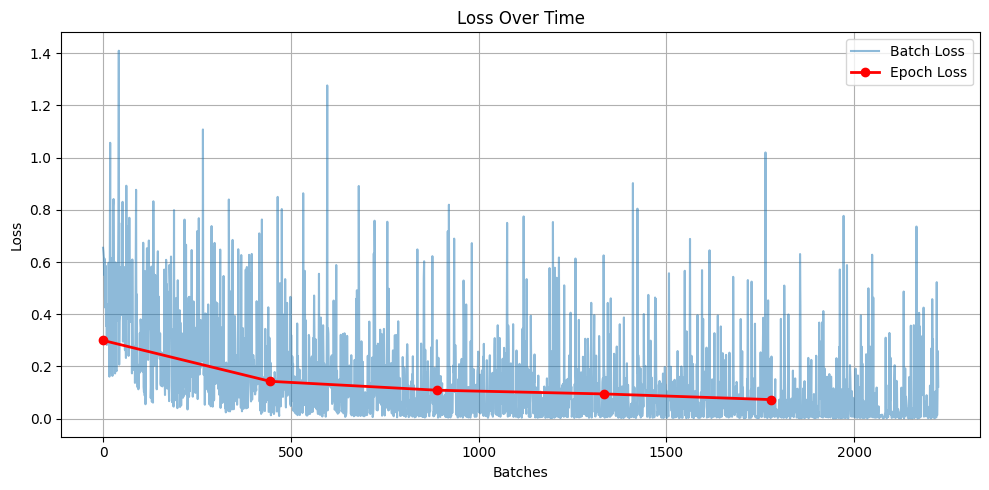

In [4]:
import pandas as pd
import torch
import time
import sys
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from transformers import DistilBertTokenizer, DistilBertForSequenceClassification

# Load dataset
file_path = "data/dataset_final_train.csv"
df = pd.read_csv(file_path)

# Convert string list in Candidates column back to Python lists
import ast

df["Candidates"] = df["Candidates"].apply(ast.literal_eval)

# Initialize tokenizer
tokenizer = DistilBertTokenizer.from_pretrained("distilbert-base-uncased")


# Define dataset class
class FlightRankingDataset(Dataset):
    def __init__(self, dataframe, tokenizer, max_length=128):
        self.data = []
        self.tokenizer = tokenizer
        self.max_length = max_length

        for _, row in dataframe.iterrows():
            request = row["Request"]
            correct_flight = row["Flight"]
            candidates = row["Candidates"]

            for candidate in candidates:
                label = 1 if candidate == correct_flight else 0
                self.data.append((request, candidate, label))

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        request, candidate, label = self.data[idx]

        input_text = f"{request} [SEP] {candidate}"

        encodings = self.tokenizer(
            input_text,
            padding="max_length",
            truncation=True,
            max_length=self.max_length,
            return_tensors="pt",
        )

        return {
            "input_ids": encodings["input_ids"].squeeze(0),
            "attention_mask": encodings["attention_mask"].squeeze(0),
            "labels": torch.tensor(label, dtype=torch.float),
        }


# Create dataset
dataset = FlightRankingDataset(df, tokenizer)
dataloader = DataLoader(dataset, batch_size=8, shuffle=True)

# Define model
model = DistilBertForSequenceClassification.from_pretrained(
    "distilbert-base-uncased", num_labels=1
)

# Define optimizer & loss
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-5)
loss_fn = torch.nn.BCEWithLogitsLoss()

# Move model to MPS if available
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
model.to(device)

# Training loop with progress tracking
num_epochs = 5
epoch_losses = []  # Store loss per epoch
batch_losses = []  # Store loss per batch

print(f"🚀 Starting training for {num_epochs} epochs on {device}...\n")

for epoch in range(num_epochs):
    model.train()
    total_loss = 0
    start_time = time.time()

    for batch_idx, batch in enumerate(dataloader):
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()
        outputs = model(input_ids, attention_mask=attention_mask)
        loss = loss_fn(outputs.logits.squeeze(), labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        batch_losses.append(loss.item())

        # Live update on same line
        sys.stdout.write(
            f"\r🔄 Epoch [{epoch+1}/{num_epochs}] - Batch [{batch_idx+1}/{len(dataloader)}] - Loss: {loss.item():.4f}"
        )
        sys.stdout.flush()

    avg_epoch_loss = total_loss / len(dataloader)
    epoch_losses.append(avg_epoch_loss)

    elapsed_time = time.time() - start_time
    print(
        f"\r✅ Epoch {epoch+1}/{num_epochs} complete! Avg Loss: {avg_epoch_loss:.4f} - Time: {elapsed_time:.2f}s"
    )

# Save the trained model
model.save_pretrained("bert_flight_ranking")
tokenizer.save_pretrained("bert_flight_ranking")

print("🎯 Training complete! Model saved as 'bert_flight_ranking'.")

import numpy as np

# Prepare x-axis values
batch_x = list(range(len(batch_losses)))
epoch_x = np.linspace(0, len(batch_losses), num=num_epochs, endpoint=False)

# Plot loss over time
plt.figure(figsize=(10, 5))
plt.plot(batch_x, batch_losses, label="Batch Loss", alpha=0.5)
plt.plot(
    epoch_x, epoch_losses, label="Epoch Loss", marker="o", linewidth=2, color="red"
)

plt.xlabel("Batches")
plt.ylabel("Loss")
plt.title("Loss Over Time")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Evaluate Model
- Top-1 Accuracy: % of times the correct flight is ranked 1st by the model.
- Top-3 Accuracy: % of times the correct flight appears in the top 3 ranked candidates.
- MRR (Mean Reciprocal Rank): Average of 1 / rank of the correct flight — rewards higher rankings more.

In [5]:
import pandas as pd
import torch
from transformers import DistilBertTokenizer, DistilBertForSequenceClassification
from tqdm import tqdm
import ast

# Load model and tokenizer
model_path = "bert_flight_ranking"
tokenizer = DistilBertTokenizer.from_pretrained(model_path)
model = DistilBertForSequenceClassification.from_pretrained(model_path)

# Load test set
df = pd.read_csv("data/dataset_final_test.csv")
df["Candidates"] = df["Candidates"].apply(ast.literal_eval)

# Set device
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
model.to(device)
model.eval()


def infer_flight(request, candidates):
    input_texts = [f"{request} [SEP] {candidate}" for candidate in candidates]

    encodings = tokenizer(
        input_texts, padding=True, truncation=True, return_tensors="pt"
    ).to(device)

    with torch.no_grad():
        outputs = model(**encodings)

    scores = outputs.logits.squeeze().tolist()

    if isinstance(scores, float):  # In case of a single candidate
        scores = [scores]

    ranked_candidates = sorted(
        zip(candidates, scores), key=lambda x: x[1], reverse=True
    )

    return ranked_candidates


# Evaluation metrics
correct_top1 = 0
correct_top3 = 0
reciprocal_ranks = []

print("🔍 Evaluating on test set...\n")

for _, row in tqdm(df.iterrows(), total=len(df)):
    request = row["Request"]
    true_flight = row["Flight"]
    candidates = row["Candidates"]

    ranked = infer_flight(request, candidates)
    ranked_flights = [flight for flight, _ in ranked]

    # Accuracy@1
    if ranked_flights[0] == true_flight:
        correct_top1 += 1

    # Accuracy@3
    if true_flight in ranked_flights[:3]:
        correct_top3 += 1

    # MRR
    try:
        rank = ranked_flights.index(true_flight) + 1
        reciprocal_ranks.append(1.0 / rank)
    except ValueError:
        reciprocal_ranks.append(0.0)

# Final scores
accuracy_top1 = correct_top1 / len(df)
accuracy_top3 = correct_top3 / len(df)
mrr = sum(reciprocal_ranks) / len(reciprocal_ranks)

print(f"\n✅ Evaluation complete!")
print(f"🎯 Accuracy@1: {accuracy_top1:.4f}")
print(f"🎯 Accuracy@3: {accuracy_top3:.4f}")
print(f"🎯 MRR:        {mrr:.4f}")

🔍 Evaluating on test set...



100%|██████████| 80/80 [00:01<00:00, 41.48it/s]


✅ Evaluation complete!
🎯 Accuracy@1: 0.9625
🎯 Accuracy@3: 1.0000
🎯 MRR:        0.9792
